# Segmentace denních profilů spotřeby elektřiny: k-means a Wardovo hierarchické shlukování

Semestrální práce z předmětu Strojové učení 1. Varianta B: jeden datový zdroj a dva různé postupy. Zdroj jsou londýnské chytré elektroměry z projektu Low Carbon London. Postupy jsou k-means a hierarchické shlukování s Wardovou vazbou.

Notebook je výpočet a prezentace modelu. Rovnice, definice vzorku a souhrn výsledků jsou v `dokumentace.md`. Čísla v textu patří k běhu na přiložených blocích se semenem 42. Když tyto soubory chybí, načítací buňka spustí označenou miniaturní náhradu a čísla v textu pro ten běh neplatí.

## 1. Cíl a výzkumná otázka

Cílem je zjistit, jestli se dny domácností skládají do opakovaných tvarů odběru, a který ze dvou klasických postupů takový popis na stejných datech podá přesvědčivěji.

Výzkumná otázka: lze denní profily spotřeby elektřiny v domácnostech rozdělit do smysluplných skupin (ranní špička, večerní špička, plochý odběr a podobně) a který z postupů — k-means, nebo hierarchické shlukování s Wardovou vazbou — to dělá lépe?

„Lépe“ zde znamená vyšší siluetový koeficient, nižší Davies–Bouldinův index, stabilnější přiřazení a čitelnější průměrný profil. Správné štítky k dnům nejsou, takže výsledkem není přesnost klasifikace. Neuronové sítě ani druhý datový zdroj do práce nepatří.

Jednotka analýzy je domácnost-den: 24 hodinových spotřeb v kWh. Identifikátor domácnosti, den v týdnu a roční období ve shlukování nejsou. Den v týdnu a sezóna slouží až k dodatečnému popisu.

## 2. Data a vzorek

Měření pocházejí z projektu UK Power Networks Low Carbon London a jsou zveřejněná jako *SmartMeter Energy Consumption Data in London Households* na [London Datastore](https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households/). Půlhodinová spotřeba v kWh pokrývá 5 567 domácností od listopadu 2011 do února 2014. Stejná měření jsou na Kaggle pod názvem [*Smart meters in London*](https://www.kaggle.com/datasets/jeanmidev/smart-meters-in-london) (Jean-Michel D); stažení odtud chce API token, který tento notebook nepoužívá a nevymýšlí.

Pracovní výřez jsou čtyři souvislé bloky z archivu *Partitioned LCL Data* (168 souborů po milionu řádků, dohromady stovky MB): `LCL-June2015v2_0.csv` až `LCL-June2015v2_3.csv` ve složce `Small LCL Data`. V repozitáři práce leží jako gzip vedle notebooku, ve složce `data/`. Sloupce jsou `LCLid`, `stdorToU`, `DateTime` a `KWH/hh (per half hour)`.

Pravidlo vzorku:

- domácnosti jsou souvislý úsek identifikátorů v těchto čtyřech blocích, ne los ze všech 5 567 domácností; na plánovaných zhruba 80–150 domácností to stačí a Wardovo shlukování je vůči počtu profilů kvadratické,
- poslední identifikátor v posledním bloku je uťatý hranicí souboru (pokračoval by v bloku 4), proto ze vzorku vypadne,
- ve vzorku zůstává jen standardní tarif `Std`, aby do tvaru dne nevstupoval dynamický cenový signál z roku 2013,
- rok je 2013,
- den zůstane jen tehdy, když má právě jednou každou z 48 půlhodin od 00:00 do 23:30; chybějící slot, duplicita, Null nebo razítko mimo mřížku den vyřadí, nic se nedoplňuje,
- den s nulovým součtem vypadne, protože u něj L2 normalizace nemá smysl,
- z platných dní vznikne náhodný podvýběr nejvýše 5 000 profilů, semeno 42.

Když bloky na disku nejsou, stačí do `data/` položit buď tyto čtyři soubory (csv nebo csv.gz), nebo jeden soubor `data/hh_blocks.csv` se stejnými sloupci. Kaggle export `halfhourly_dataset/block_*.csv` má sloupce `LCLid`, `tstp`, `energy(kWh/hh)`; loader ty názvy přijme, soubor je ale potřeba složit ručně. Bez souboru naběhne náhrada a buňka to napíše velkým varováním.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    silhouette_score,
)

SEED = 42
MAX_PROFILES = 5000
K_GRID = list(range(2, 9))
BLOCKS = (0, 1, 2, 3)
# True jen pro ruční zkoušku náhrady. Při False se náhrada spustí sama, když soubory chybí.
FORCE_SYNTHETIC = False

np.random.seed(SEED)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
})
COLORS = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

import matplotlib
import scipy
import sklearn

print(
    f"numpy {np.__version__} | pandas {pd.__version__} | "
    f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | "
    f"matplotlib {matplotlib.__version__}"
)
print(f"semeno = {SEED}, strop profilů = {MAX_PROFILES}")

numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2
semeno = 42, strop profilů = 5000


In [2]:
def resolve_data_dir() -> Path:
    for candidate in (Path("data"), Path("/cursor/stores/self/docs/data")):
        if candidate.exists():
            return candidate
    return Path("data")


def find_inputs(data_dir: Path):
    blocks = []
    for i in BLOCKS:
        for suffix in (".csv", ".csv.gz"):
            path = data_dir / f"LCL-June2015v2_{i}{suffix}"
            if path.exists():
                blocks.append(path)
                break
    if len(blocks) == len(BLOCKS):
        return blocks, "blocks"
    for name in ("hh_blocks.csv", "hh_blocks.csv.gz"):
        path = data_dir / name
        if path.exists():
            return [path], "hh_blocks"
    return [], "missing"


def synthesize_half_hourly(seed: int = SEED) -> pd.DataFrame:
    """Miniaturní náhrada s čtyřmi vtisknutými tvary. Není to Londýn."""
    rng = np.random.default_rng(seed)
    hours = np.arange(24)
    flat = np.full(24, 1.0 / 24.0)
    night = np.exp(-0.5 * ((hours - 1) / 2.0) ** 2)
    night = night / night.sum()
    evening = np.exp(-0.5 * ((hours - 19) / 1.8) ** 2)
    evening = 0.25 * flat + 0.75 * (evening / evening.sum())
    morning = np.exp(-0.5 * ((hours - 8) / 1.5) ** 2)
    morning = 0.30 * flat + 0.70 * (morning / morning.sum())
    catalog = (night, flat, evening, morning)
    rows = []
    for h_i in range(36):
        lid = f"SYN{h_i:03d}"
        shape = catalog[h_i % 4]
        scale = float(rng.uniform(8.0, 16.0))
        for day_i in range(40):
            day = pd.Timestamp("2013-01-06") + pd.Timedelta(days=day_i)
            noise = rng.normal(1.0, 0.06, size=24)
            profile = np.clip(shape * scale * noise, 0, None)
            for hour, value in enumerate(profile):
                for minute, frac in ((0, 0.48), (30, 0.52)):
                    stamp = day + pd.Timedelta(hours=int(hour), minutes=minute)
                    rows.append((lid, "Std", stamp.strftime("%Y-%m-%d %H:%M:%S"), f"{value * frac:.4f}"))
    frame = pd.DataFrame(rows, columns=["LCLid", "stdorToU", "DateTime", "KWH/hh (per half hour)"])
    frame.loc[0, "KWH/hh (per half hour)"] = "Null"
    frame = frame.drop(index=[4, 5])
    return frame.reset_index(drop=True)


def standardize_columns(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame.columns = [str(column).strip() for column in frame.columns]
    rename = {}
    kwh_name = None
    for column in frame.columns:
        lowered = column.lower()
        if lowered == "tstp":
            rename[column] = "DateTime"
        elif lowered.startswith("kwh") or lowered.startswith("energy"):
            kwh_name = column
    frame = frame.rename(columns=rename)
    if kwh_name is not None:
        frame = frame.rename(columns={kwh_name: "kwh"})
    missing = [name for name in ("LCLid", "DateTime", "kwh") if name not in frame.columns]
    if missing:
        raise ValueError(f"V datech chybí sloupce: {missing}")
    return frame


def load_measurements(data_dir: Path):
    paths, kind = find_inputs(data_dir)
    if FORCE_SYNTHETIC or kind == "missing":
        frame = standardize_columns(synthesize_half_hourly())
        info = {
            "source": "synthetic",
            "paths": [],
            "truncated_id": None,
        }
        print("POZOR: NÁHRADA, NE SKUTEČNÝ LONDÝN.")
        print(
            "Soubory LCL-June2015v2_0..3 ani data/hh_blocks.csv tu nejsou "
            "(nebo je zapnuté FORCE_SYNTHETIC)."
        )
        print(
            "Níže běží miniaturní generátor čtyř tvarů. Nejsou to londýnská měření "
            "a nejde o odevzdatelný závěr práce."
        )
        return frame, info
    frames = [standardize_columns(pd.read_csv(path)) for path in paths]
    frame = pd.concat(frames, ignore_index=True)
    info = {"source": kind, "paths": paths, "truncated_id": None}
    if kind == "blocks":
        # Poslední řádek posledního bloku patří domácnosti, která pokračuje v dalším souboru.
        info["truncated_id"] = str(frame["LCLid"].iloc[-1])
        frame = frame.loc[frame["LCLid"] != info["truncated_id"]].copy()
    print("ZDROJ: skutečná měření Low Carbon London (London Datastore).")
    print("Soubory:", ", ".join(path.name for path in paths))
    if info["truncated_id"]:
        print(f"Vyřazená domácnost uťatá hranicí bloku: {info['truncated_id']}")
    return frame, info


DATA_DIR = resolve_data_dir()
raw_frame, SOURCE = load_measurements(DATA_DIR)
print(f"Složka dat: {DATA_DIR.resolve()}")
if SOURCE["truncated_id"]:
    label = "Řádků po vyřazení uťaté domácnosti"
else:
    label = "Řádků"
print(f"{label}: {len(raw_frame):,}".replace(",", " "))
print(f"Domácností v načteném rámci: {raw_frame['LCLid'].nunique()}")

ZDROJ: skutečná měření Low Carbon London (London Datastore).
Soubory: LCL-June2015v2_0.csv.gz, LCL-June2015v2_1.csv.gz, LCL-June2015v2_2.csv.gz, LCL-June2015v2_3.csv.gz
Vyřazená domácnost uťatá hranicí bloku: MAC000131
Složka dat: /cursor/stores/bc-80062188-08fc-47a0-a25e-f7af54258e4a/docs/data
Řádků po vyřazení uťaté domácnosti: 3 971 842
Domácností v načteném rámci: 108


In [3]:
work = raw_frame.copy()
work["kwh"] = pd.to_numeric(work["kwh"], errors="coerce")
work["ts"] = pd.to_datetime(work["DateTime"].astype(str).str.slice(0, 19), errors="coerce")
n_before = len(work)
# Platná půlhodina: konečné nezáporné kWh a razítko přesně v :00 nebo :30.
valid = (
    work["kwh"].notna()
    & work["ts"].notna()
    & work["ts"].dt.minute.isin([0, 30])
    & work["ts"].dt.second.eq(0)
    & work["kwh"].ge(0)
)
n_invalid = int((~valid).sum())
work = work.loc[valid].copy()

if "stdorToU" in work.columns:
    tariff = work["stdorToU"].astype(str).str.strip()
    print("Tarify před filtrem Std:", tariff.value_counts().to_dict())
    work = work.loc[tariff.eq("Std")].copy()
else:
    print("Sloupec stdorToU v souboru není, filtr tarifu proto nejde udělat.")

work["day"] = work["ts"].dt.normalize()
work["hour"] = work["ts"].dt.hour
print(f"Vyřazeno řádků mimo mřížku, s Null nebo se zápornou hodnotou: {n_invalid} z {n_before}")
print(f"Rozsah razítek po čištění: {work['ts'].min()} až {work['ts'].max()}")
print(f"Domácností na standardním tarifu: {work['LCLid'].nunique()}")

year = work.loc[(work["day"] >= "2013-01-01") & (work["day"] <= "2013-12-31")].copy()
print(f"Rok 2013: {len(year):,} řádků, {year['LCLid'].nunique()} domácností".replace(",", " "))

counts = year.groupby(["LCLid", "day"], sort=True)["ts"].agg(n_rows="size", n_unique="nunique")
complete = (counts["n_rows"] == 48) & (counts["n_unique"] == 48)
print(f"Domácnost-dnů v roce 2013: {len(counts)}")
print(f"Z toho kompletních 48 půlhodin: {int(complete.sum())}")
print(f"Vyřazeno nekompletních dnů: {int((~complete).sum())}")

kept = year.set_index(["LCLid", "day"]).loc[counts.index[complete]].reset_index()
hourly = kept.groupby(["LCLid", "day", "hour"], as_index=False)["kwh"].sum()
profiles = (
    hourly.pivot(index=["LCLid", "day"], columns="hour", values="kwh")
    .reindex(columns=range(24))
    .sort_index()
)
if profiles.isna().any().any():
    raise RuntimeError("U kompletního dne chybí hodina. Filtr 48 slotů se rozešel se součtem.")
n_zero = int((profiles.sum(axis=1) <= 0).sum())
profiles = profiles.loc[profiles.sum(axis=1) > 0]
print(f"Vyřazeno dnů s nulovým součtem: {n_zero}")
print(f"Platných profilů: {len(profiles)}")
print(f"Domácností s aspoň jedním platným dnem: {profiles.index.get_level_values(0).nunique()}")

Tarify před filtrem Std: {'Std': 3971734}


Vyřazeno řádků mimo mřížku, s Null nebo se zápornou hodnotou: 108 z 3971842
Rozsah razítek po čištění: 2011-12-06 13:00:00 až 2014-02-28 00:00:00
Domácností na standardním tarifu: 108


Rok 2013: 1 811 291 řádků  108 domácností


Domácnost-dnů v roce 2013: 37742
Z toho kompletních 48 půlhodin: 36271
Vyřazeno nekompletních dnů: 1471


Vyřazeno dnů s nulovým součtem: 312
Platných profilů: 35959
Domácností s aspoň jedním platným dnem: 108


## 3. Předzpracování

Razítko v těchto souborech leží uvnitř kalendářního dne od 00:00 do 23:30. Hodina 0 je součet půlhodin 00:00 a 00:30, hodina 23 je součet 23:00 a 23:30. Posun o půl hodiny zpět by dával smysl jen tehdy, kdyby půlnoc patřila předchozímu dni. Tady na jeden den patří oba konce.

Den bez kompletní mřížky se zahazuje. Doplnění průměrem by tvar dne vyrobilo z okolních hodin a shluky by pak četly i tuto opravu. Nuly v součtu dne zůstávají stranou ze stejného důvodu: dělení nulovou normou není tvar odběru.

Normalizace je L2. Vektor 24 hodin se dělí svou eukleidovskou délkou, takže dva dny se stejným tvarem a jinou úrovní spadnou k sobě. Průměr v původních kWh se počítá z členů shluku zvlášť a v interpretaci stojí vedle tvaru. Velikost domácnosti je v modelu schovaná, v popisu ne.

Z platných dní vzniká náhodný podvýběr nejvýše 5 000 řádků. To je matice, kterou dostanou obě metody. Den v týdnu a sezóna zůstávají mimo matici a slouží jen k popisu. Sezóna je meteorologická: zima je prosinec až únor, jaro březen až květen, léto červen až srpen, podzim zbytek.

In [4]:
rng = np.random.default_rng(SEED)
raw_all = profiles.to_numpy(dtype=float)
if len(raw_all) > MAX_PROFILES:
    chosen = rng.choice(len(raw_all), size=MAX_PROFILES, replace=False)
else:
    chosen = np.arange(len(raw_all))
raw = raw_all[chosen]
meta = profiles.index[chosen]
norms = np.linalg.norm(raw, axis=1)
if np.any(norms <= 0):
    raise RuntimeError("V matici zustal den s nulovou normou.")
X = raw / norms[:, None]

days = pd.DatetimeIndex(pd.to_datetime(meta.get_level_values(1)))
households = meta.get_level_values(0).to_numpy()
weekday = days.day_of_week
month = days.month
season_labels = np.where(
    np.isin(month, [12, 1, 2]),
    "zima",
    np.where(np.isin(month, [3, 4, 5]), "jaro", np.where(np.isin(month, [6, 7, 8]), "léto", "podzim")),
)

print(f"Matice pro shlukování: {X.shape[0]} dní × {X.shape[1]} hodin")
print(f"Domácností v matici: {len(np.unique(households))}")
print(f"Průměrná denní spotřeba ve vzorku: {raw.sum(axis=1).mean():.2f} kWh")
print(f"Medián denní spotřeby: {np.median(raw.sum(axis=1)):.2f} kWh")
print("Zdroj matice:", "bloky London Datastore" if SOURCE["source"] == "blocks" else SOURCE["source"])

Matice pro shlukování: 5000 dní × 24 hodin
Domácností v matici: 107
Průměrná denní spotřeba ve vzorku: 11.57 kWh
Medián denní spotřeby: 8.75 kWh
Zdroj matice: bloky London Datastore


## 4. Volba k

k se vybírá jen z k-means, na téže matici, kterou pak dostane i Ward. Pro k od 2 do 8 model spočítá setrvačnost (součet čtverců uvnitř shluků, tu k-means přímo minimalizuje) a siluetový koeficient na celé matici. Zvolené k je to s nejvyšší siluetou. Loket setrvačnosti slouží jako kontrola, že maximum siluety nesedí na náhodném zoubku úplně mimo zlom křivky. Po této volbě se k už nemění podle toho, které metodě by jiné k víc slušelo.

Silueta kolem jedné desetiny je u denních profilů očekávatelná: tvary se překrývají a den není čistá koule kolem jednoho centroidu. Rozdíl mezi sousedními k je proto jen pravidlo výběru. Skupiny kvůli němu ještě nejsou ostře oddělené.

In [5]:
inertias = []
silhouettes = []
for k in K_GRID:
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED, algorithm="lloyd")
    labels_k = model.fit_predict(X)
    inertias.append(float(model.inertia_))
    silhouettes.append(float(silhouette_score(X, labels_k, metric="euclidean")))
    print(f"k = {k:d}  setrvačnost = {inertias[-1]:8.1f}  silueta = {silhouettes[-1]:.4f}")

k_star = K_GRID[int(np.argmax(silhouettes))]
print(f"Zvolené k = {k_star} (maximum siluety k-means). Pro obě metody už zůstává fixní.")

k = 2  setrvačnost =   1291.6  silueta = 0.0907
k = 3  setrvačnost =   1193.8  silueta = 0.1013


k = 4  setrvačnost =   1125.6  silueta = 0.0964
k = 5  setrvačnost =   1071.2  silueta = 0.0972


k = 6  setrvačnost =   1028.1  silueta = 0.0977


k = 7  setrvačnost =    988.8  silueta = 0.1011
k = 8  setrvačnost =    959.8  silueta = 0.1000
Zvolené k = 3 (maximum siluety k-means). Pro obě metody už zůstává fixní.


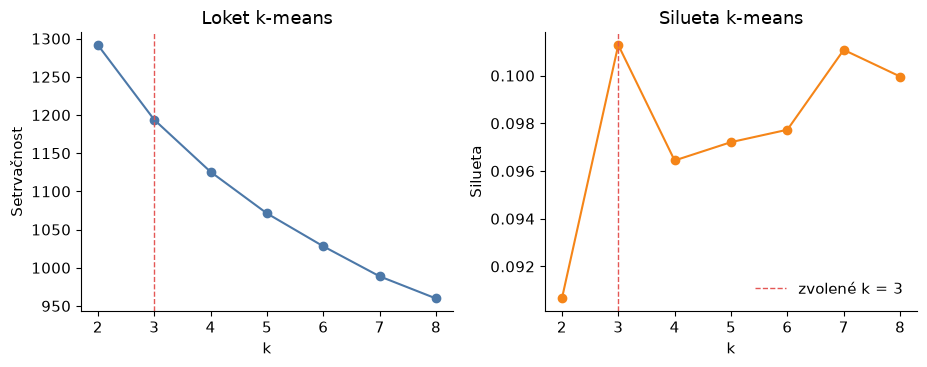

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
axes[0].plot(K_GRID, inertias, marker="o", color=COLORS[0])
axes[0].axvline(k_star, color=COLORS[3], ls="--", lw=1)
axes[0].set_xlabel("k")
axes[0].set_ylabel("Setrvačnost")
axes[0].set_title("Loket k-means")
axes[0].set_xticks(K_GRID)
axes[1].plot(K_GRID, silhouettes, marker="o", color=COLORS[1])
axes[1].axvline(k_star, color=COLORS[3], ls="--", lw=1, label=f"zvolené k = {k_star}")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silueta")
axes[1].set_title("Silueta k-means")
axes[1].set_xticks(K_GRID)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)

Na této matici má silueta maximum u k = 3 (0,1013). Druhé je k = 7 (0,1011): na tři desetinná místa vypadají stejně, pravidlo bez zaokrouhlení bere přísně vyšší hodnotu, tedy 3. Setrvačnost klesá pořád, nejprudší schod je mezi k = 2 a k = 3 a dál už bez druhého ostrého lokte. k = 3 tedy není ruční výběr podle obrázků. Kdyby maximum vyšlo jinam, obrázky v dalších částech by patřily tomu jinému k; text závěru popisuje tento běh.

Absolutní silueta 0,10 znamená, že i zvolené k je hrubý popis. Skupiny se prolínají.

## 5. K-means

K-means na L2 matici minimalizuje součet čtverců kolem centroidů. Hlavní model má `n_init=10` a semeno 42: z deseti náhodných startů zůstane běh s nejmenší setrvačností. To je jediný k-means v porovnání.

Stabilita inicializace je jiný, schválně slabší běh. Dva modely s `n_init=1` a semeny 42 a 43 přiřadí tytéž body a shodu měří upravený Randův index (ARI). ARI nezávisí na přečíslování štítků. Vysoké ARI znamená, že start skoro nemění řez. Nízké by znamenalo, že „výsledek k-means“ je artefakt jednoho startu. Tento pár není druhá metoda ve smyslu zadání.

Jméno shluku je čtecí pomůcka z průměrného profilu v kWh, ne další model. Noční odběr je vrchol v hodinách 0–4 nebo aspoň 35 % energie v hodinách 0–5. Večerní špička je vrchol v hodině 16 nebo později a aspoň 30 % energie v hodinách 17–21. Ranní špička je vrchol mezi 6 a 9 a aspoň 28 % energie v hodinách 6–9. Jinak jde o rozložený denní odběr. Při shodě jmen se ke jménu přidá hodina vrcholu.

ARI dvou samostatných inicializací k-means (n_init=1, semena 42 a 43): 0.934
Setrvačnost hlavního modelu (n_init=10): 1193.8


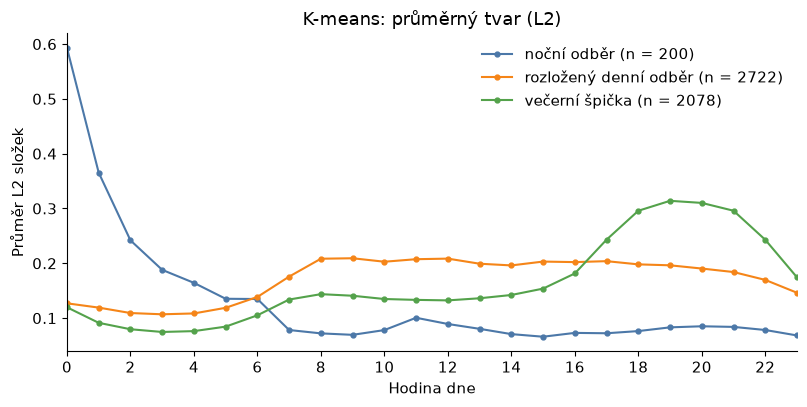

In [7]:
def describe_profile(mean_raw: np.ndarray) -> str:
    total = float(mean_raw.sum())
    if total <= 0:
        return "prázdný profil"
    night = float(mean_raw[:6].sum()) / total
    morning = float(mean_raw[6:10].sum()) / total
    evening = float(mean_raw[17:22].sum()) / total
    peak = int(np.argmax(mean_raw))
    if night >= 0.35 or peak <= 4:
        return "noční odběr"
    if evening >= 0.30 and peak >= 16:
        return "večerní špička"
    if morning >= 0.28 and 6 <= peak <= 9:
        return "ranní špička"
    return "rozložený denní odběr"


def name_clusters(raw_matrix: np.ndarray, labels: np.ndarray) -> dict:
    names = {}
    for cluster in np.unique(labels):
        names[int(cluster)] = describe_profile(raw_matrix[labels == cluster].mean(axis=0))
    used = {}
    for cluster, name in names.items():
        used[name] = used.get(name, 0) + 1
    if any(count > 1 for count in used.values()):
        for cluster, name in list(names.items()):
            if used[name] > 1:
                peak = int(np.argmax(raw_matrix[labels == cluster].mean(axis=0)))
                names[cluster] = f"{name} (vrchol {peak:02d} h)"
    return names


def ordered_ids(raw_matrix: np.ndarray, labels: np.ndarray, names: dict) -> list:
    return sorted(names, key=lambda cluster: int(np.argmax(raw_matrix[labels == cluster].mean(axis=0))))


def plot_profiles(series_by_name, title: str, ylabel: str) -> None:
    fig, ax = plt.subplots(figsize=(8.2, 4.2))
    hours = np.arange(24)
    for i, (name, series) in enumerate(series_by_name):
        ax.plot(hours, series, marker="o", ms=3.5, color=COLORS[i % len(COLORS)], label=name)
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hodina dne")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


kmeans = KMeans(n_clusters=k_star, n_init=10, random_state=SEED, algorithm="lloyd")
labels_km = kmeans.fit_predict(X)
names_km = name_clusters(raw, labels_km)
order_km = ordered_ids(raw, labels_km, names_km)

init_a = KMeans(n_clusters=k_star, n_init=1, random_state=SEED, algorithm="lloyd").fit_predict(X)
init_b = KMeans(n_clusters=k_star, n_init=1, random_state=SEED + 1, algorithm="lloyd").fit_predict(X)
ari_km_init = float(adjusted_rand_score(init_a, init_b))
print(f"ARI dvou samostatných inicializací k-means (n_init=1, semena {SEED} a {SEED + 1}): {ari_km_init:.3f}")
print(f"Setrvačnost hlavního modelu (n_init=10): {kmeans.inertia_:.1f}")

shape_km = []
for cluster in order_km:
    mean_shape = X[labels_km == cluster].mean(axis=0)
    count = int((labels_km == cluster).sum())
    shape_km.append((f"{names_km[cluster]} (n = {count})", mean_shape))
plot_profiles(shape_km, "K-means: průměrný tvar (L2)", "Průměr L2 složek")

## 6. Hierarchické shlukování (Ward)

Wardova vazba spojuje v každém kroku dvojici, u které nejméně naroste součet čtverců. Vstup je tatáž L2 matice. Řez bere `fcluster` s `criterion="maxclust"` a s k zafixovaným v části 4. Dendrogram níže je zkrácený vrchol téhož stromu (posledních 12 spojení), ne shlukování jiného vzorku. Barvy v dendrogramu jsou jen orientační; štítky pro metriky jdou z řezu, ne z obrázku.

Stabilita Wardova řezu se měří jinak než u k-means, protože tu není náhodná inicializace centroidů. Dva nezávislé podvýběry 60 % profilů (semena 11 a 12) dostanou každý vlastní Wardův strom, řez na stejné k a ARI na průniku dní. Nízké ARI znamená, že řez závisí na tom, které dny ve vzorku zrovna jsou. Není to porovnání s k-means; to je až v další části.

ARI dvou Wardových řezů na podvýběrech 60 % (n = 3000, průnik 1776 dní, semena 11 a 12): 0.259


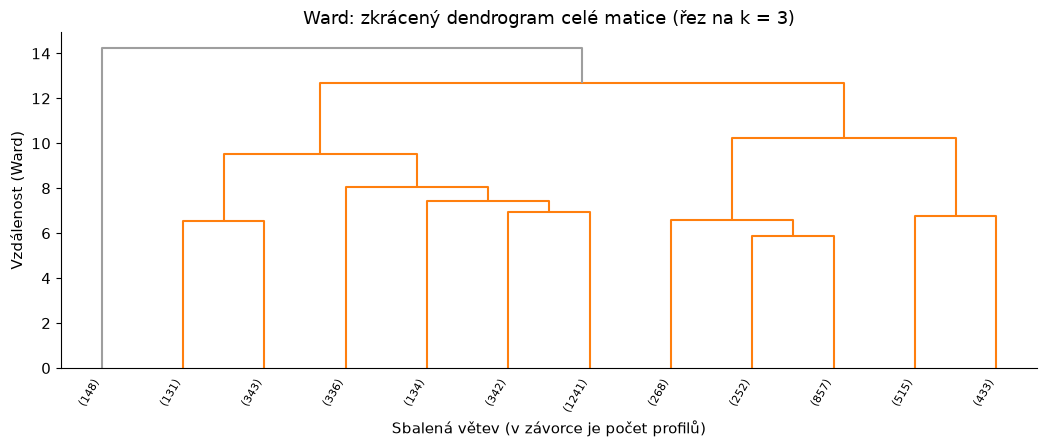

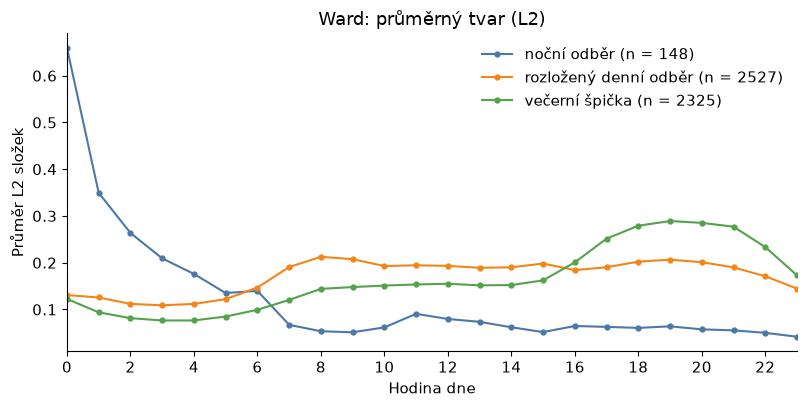

In [8]:
def ward_subsample_ari(matrix: np.ndarray, k: int, seed_a: int, seed_b: int, frac: float = 0.6):
    def cut(seed: int):
        sub_rng = np.random.default_rng(seed)
        n_sub = int(frac * len(matrix))
        # Setřídění jen drží pořadí řádků stejné při opakovaném běhu; množina bodů je náhodná.
        index = np.sort(sub_rng.choice(len(matrix), size=n_sub, replace=False))
        sub_labels = fcluster(linkage(matrix[index], method="ward"), t=k, criterion="maxclust")
        return index, sub_labels

    index_a, labels_a = cut(seed_a)
    index_b, labels_b = cut(seed_b)
    common = np.intersect1d(index_a, index_b)
    pos_a = {int(idx): pos for pos, idx in enumerate(index_a)}
    pos_b = {int(idx): pos for pos, idx in enumerate(index_b)}
    paired_a = np.array([labels_a[pos_a[int(idx)]] for idx in common])
    paired_b = np.array([labels_b[pos_b[int(idx)]] for idx in common])
    return float(adjusted_rand_score(paired_a, paired_b)), int(len(common)), int(len(index_a))


Z = linkage(X, method="ward")
labels_ward = fcluster(Z, t=k_star, criterion="maxclust")
names_ward = name_clusters(raw, labels_ward)
order_ward = ordered_ids(raw, labels_ward, names_ward)
ari_ward_sub, n_common, n_sub = ward_subsample_ari(X, k_star, 11, 12)
print(
    f"ARI dvou Wardových řezů na podvýběrech 60 % "
    f"(n = {n_sub}, průnik {n_common} dní, semena 11 a 12): {ari_ward_sub:.3f}"
)

fig, ax = plt.subplots(figsize=(10.6, 4.6))
# Práh barvy mezi spojením na k shluků a spojením, které k sníží o jedničku.
height_keep = Z[-(k_star - 1), 2]
height_merge = Z[-(k_star - 2), 2]
dendrogram(
    Z,
    truncate_mode="lastp",
    p=12,
    color_threshold=(height_keep + height_merge) / 2,
    above_threshold_color="#9e9e9e",
    ax=ax,
)
ax.set_title(f"Ward: zkrácený dendrogram celé matice (řez na k = {k_star})")
ax.set_xlabel("Sbalená větev (v závorce je počet profilů)")
ax.set_ylabel("Vzdálenost (Ward)")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

shape_ward = []
for cluster in order_ward:
    count = int((labels_ward == cluster).sum())
    shape_ward.append((f"{names_ward[cluster]} (n = {count})", X[labels_ward == cluster].mean(axis=0)))
plot_profiles(shape_ward, "Ward: průměrný tvar (L2)", "Průměr L2 složek")

## 7. Porovnání

Obě metody mají stejné řádky, stejnou L2 normalizaci a stejné k. Silueta a Davies–Bouldinův index jsou spočítané na celé matici. Silueta se maximalizuje, Davies–Bouldinův index se minimalizuje. ARI mezi metodami říká, jestli přiřazují dny stejně; není to skóre kvality. Setrvačnost je v tabulce jen jako popis: k-means ji přímo minimalizuje, takže nižší číslo u k-means není nezávislý důkaz.

Stabilita se mezi metodami nesmí číst jako stejný experiment. U k-means jsou to dva starty na celé matici, u Warda dva podvýběry. Obojí ale odpovídá na praktickou otázku, jestli se řez při malé změně běhu rozsype.

ARI mezi k-means a Wardem na týchž dnech: 0.369


,metoda,silueta (vyšší lépe),Davies–Bouldin (nižší lépe),setrvačnost,stabilita (ARI)
0,k-means,0.101,2.377,1193.794,0.934
1,Ward,0.073,2.827,1239.665,0.259


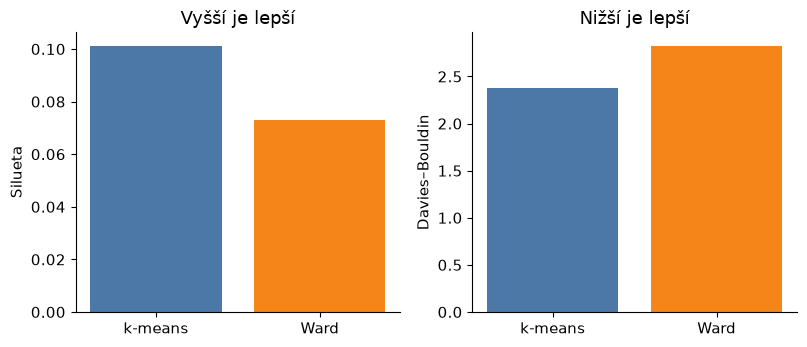

In [9]:
def within_sse(matrix: np.ndarray, labels: np.ndarray) -> float:
    total = 0.0
    for cluster in np.unique(labels):
        members = matrix[labels == cluster]
        center = members.mean(axis=0)
        total += float(((members - center) ** 2).sum())
    return total


metrics = pd.DataFrame(
    [
        {
            "metoda": "k-means",
            "silueta (vyšší lépe)": silhouette_score(X, labels_km, metric="euclidean"),
            "Davies–Bouldin (nižší lépe)": davies_bouldin_score(X, labels_km),
            "setrvačnost": within_sse(X, labels_km),
            "stabilita (ARI)": ari_km_init,
        },
        {
            "metoda": "Ward",
            "silueta (vyšší lépe)": silhouette_score(X, labels_ward, metric="euclidean"),
            "Davies–Bouldin (nižší lépe)": davies_bouldin_score(X, labels_ward),
            "setrvačnost": within_sse(X, labels_ward),
            "stabilita (ARI)": ari_ward_sub,
        },
    ]
)
ari_between = float(adjusted_rand_score(labels_km, labels_ward))
print(f"ARI mezi k-means a Wardem na týchž dnech: {ari_between:.3f}")
display(metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.6))
method_names = ["k-means", "Ward"]
sil_vals = metrics["silueta (vyšší lépe)"].to_numpy()
db_vals = metrics["Davies–Bouldin (nižší lépe)"].to_numpy()
axes[0].bar(method_names, sil_vals, color=[COLORS[0], COLORS[1]])
axes[0].set_ylabel("Silueta")
axes[0].set_title("Vyšší je lepší")
axes[1].bar(method_names, db_vals, color=[COLORS[0], COLORS[1]])
axes[1].set_ylabel("Davies–Bouldin")
axes[1].set_title("Nižší je lepší")
fig.tight_layout()
plt.show()
plt.close(fig)

## 8. Interpretace profilů

Tvar na předchozích obrázcích je průměr L2 vektorů. Ten se dobře čte jako poloha vrcholu a špatně jako kilowatthodina. Tady jsou průměry v původních kWh, takže je vidět i úroveň. Barva sleduje hodinu vrcholu uvnitř metody (nejdřívější vrchol je první barva). Stejná barva u k-means a u Warda proto není párování shluků; párování dělají jména a až potom ARI.

Den v týdnu a sezóna do modelu nevstoupily. Podíly níže jsou kontrola po shlukování: jestli večerní tvar sedí spíš na pracovní den a na temnější část roku. Vedle toho buňka spočítá, kolik domácností nese noční shluk. Když ho drží hrstka identifikátorů, je to stálý režim těch domácností, ne denní typ celého panelu.

,metoda,shluk,n,podíl,kWh/den,vrchol (h),podíl noci 0–5,podíl večera 17–21
0,k-means,noční odběr,200,0.040,18.680,0,0.639,0.097
1,k-means,rozložený denní odběr,2722,0.544,10.531,12,0.156,0.238
2,k-means,večerní špička,2078,0.416,12.246,19,0.126,0.377
3,Ward,noční odběr,148,0.030,20.667,0,0.694,0.075
4,Ward,rozložený denní odběr,2527,0.505,10.313,15,0.164,0.241
5,Ward,večerní špička,2325,0.465,12.357,19,0.128,0.357


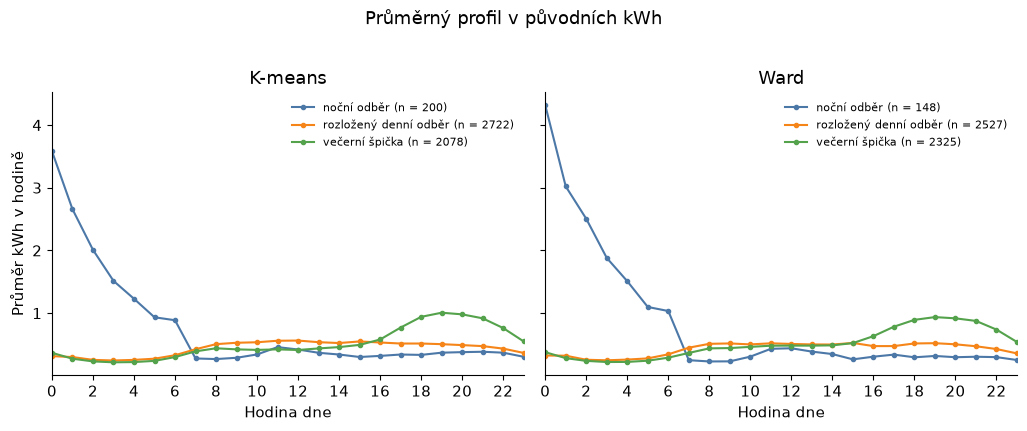

In [10]:
def cluster_table(raw_matrix, labels, names, order, method: str) -> pd.DataFrame:
    rows = []
    n = len(labels)
    for cluster in order:
        members = raw_matrix[labels == cluster]
        mean_raw = members.mean(axis=0)
        total = float(mean_raw.sum())
        rows.append(
            {
                "metoda": method,
                "shluk": names[cluster],
                "n": int(len(members)),
                "podíl": len(members) / n,
                "kWh/den": total,
                "vrchol (h)": int(np.argmax(mean_raw)),
                "podíl noci 0–5": float(mean_raw[:6].sum()) / total,
                "podíl večera 17–21": float(mean_raw[17:22].sum()) / total,
            }
        )
    return pd.DataFrame(rows)


def raw_series(raw_matrix, labels, names, order):
    series = []
    for cluster in order:
        count = int((labels == cluster).sum())
        series.append((f"{names[cluster]} (n = {count})", raw_matrix[labels == cluster].mean(axis=0)))
    return series


overview = pd.concat(
    [
        cluster_table(raw, labels_km, names_km, order_km, "k-means"),
        cluster_table(raw, labels_ward, names_ward, order_ward, "Ward"),
    ],
    ignore_index=True,
)
display(overview.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2), sharey=True)
for ax, series, title in (
    (axes[0], raw_series(raw, labels_km, names_km, order_km), "K-means"),
    (axes[1], raw_series(raw, labels_ward, names_ward, order_ward), "Ward"),
):
    for i, (name, values) in enumerate(series):
        ax.plot(np.arange(24), values, marker="o", ms=3, color=COLORS[i % len(COLORS)], label=name)
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hodina dne")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Průměr kWh v hodině")
fig.suptitle("Průměrný profil v původních kWh", y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

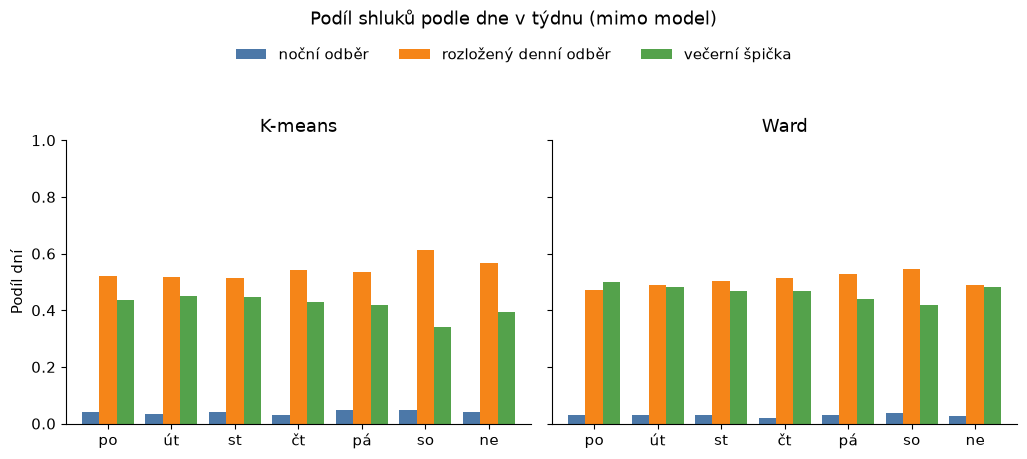

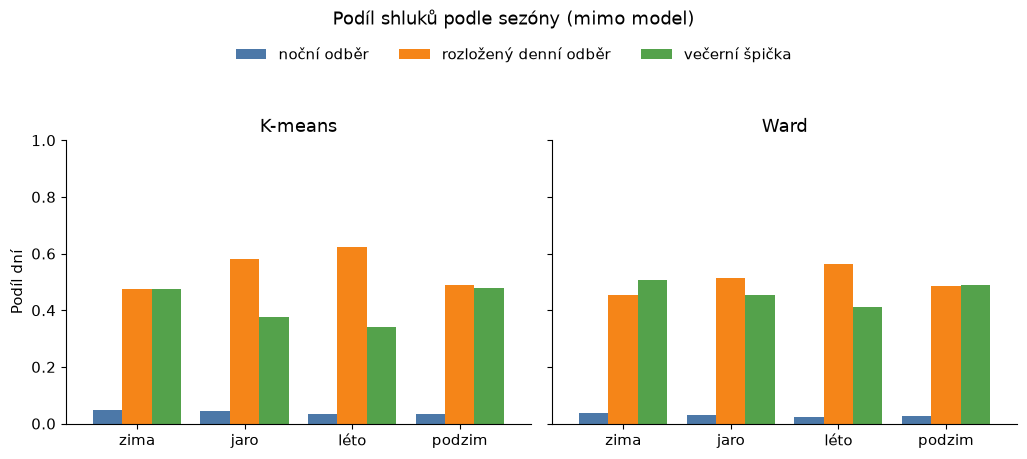

K-means, podíl podle dne v týdnu:


shluk,noční odběr,rozložený denní odběr,večerní špička
po,0.042,0.522,0.436
út,0.033,0.518,0.449
st,0.041,0.513,0.445
čt,0.030,0.542,0.428
pá,0.048,0.535,0.417
so,0.046,0.614,0.339
ne,0.039,0.567,0.394


K-means, podíl podle sezóny:


shluk,noční odběr,rozložený denní odběr,večerní špička
sezona,,,
zima,0.048,0.476,0.476
jaro,0.044,0.581,0.375
léto,0.035,0.625,0.340
podzim,0.033,0.489,0.478


Koncentrace nočního tvaru
noční odběr: 200 dní, 22 domácností, pět nejčastějších domácností pokrývá 83% těchto dní.
noční odběr: 148 dní, 10 domácností, pět nejčastějších domácností pokrývá 96% těchto dní.


In [11]:
WEEKDAYS = ["po", "út", "st", "čt", "pá", "so", "ne"]
SEASON_ORDER = ["zima", "jaro", "léto", "podzim"]


def share_frame(labels, names, order, by: np.ndarray, index_order, index_name: str) -> pd.DataFrame:
    columns = [names[cluster] for cluster in order]
    assigned = np.array([names[int(cluster)] for cluster in labels])
    frame = pd.DataFrame({index_name: by, "shluk": assigned})
    counts = pd.crosstab(frame[index_name], frame["shluk"])
    counts = counts.reindex(index=index_order, columns=columns).fillna(0)
    return counts.div(counts.sum(axis=1), axis=0)


def plot_shares(left: pd.DataFrame, right: pd.DataFrame, title: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0), sharey=True)
    for ax, frame, subtitle in ((axes[0], left, "K-means"), (axes[1], right, "Ward")):
        frame.plot(kind="bar", ax=ax, color=COLORS[: frame.shape[1]], width=0.82, legend=False)
        ax.set_title(subtitle)
        ax.set_xlabel("")
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=0)
    axes[0].set_ylabel("Podíl dní")
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
    fig.suptitle(title, y=1.14)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


km_week = share_frame(labels_km, names_km, order_km, weekday, list(range(7)), "den")
ward_week = share_frame(labels_ward, names_ward, order_ward, weekday, list(range(7)), "den")
km_week.index = WEEKDAYS
ward_week.index = WEEKDAYS
km_season = share_frame(labels_km, names_km, order_km, season_labels, SEASON_ORDER, "sezona")
ward_season = share_frame(labels_ward, names_ward, order_ward, season_labels, SEASON_ORDER, "sezona")

plot_shares(km_week, ward_week, "Podíl shluků podle dne v týdnu (mimo model)")
plot_shares(km_season, ward_season, "Podíl shluků podle sezóny (mimo model)")
print("K-means, podíl podle dne v týdnu:")
display(km_week.round(3))
print("K-means, podíl podle sezóny:")
display(km_season.round(3))


def concentration(labels, names, household_ids, prefix: str):
    matched = [cluster for cluster, name in names.items() if name.startswith(prefix)]
    if not matched:
        print(f"Shluk '{prefix}' v tomto řezu není.")
        return
    cluster = matched[0]
    owners = pd.Series(household_ids)[labels == cluster]
    counts = owners.value_counts()
    top5 = float(counts.head(5).sum() / len(owners))
    print(
        f"{names[cluster]}: {len(owners)} dní, {len(counts)} domácností, "
        f"pět nejčastějších domácností pokrývá {top5:.0%} těchto dní."
    )


print("Koncentrace nočního tvaru")
concentration(labels_km, names_km, households, "noční")
concentration(labels_ward, names_ward, households, "noční")

K-means při k = 3 dá tři tvary, které jdou pojmenovat bez násilí.

Noční odběr má 200 dní, tedy 4 % matice. Průměrný den má 18,7 kWh a asi 64 % z toho leží v hodinách 0–5. V první hodině po půlnoci je průměr kolem 3,6 kWh, přes den odběr spadne k několika desetinám. Není to „rozsvícená chodba“: úroveň je vyšší než u ostatních skupin. Jméno popisuje tvar i to, že jde o energeticky těžký režim.

Rozložený denní odběr má 2 722 dní (54 %) a průměr 10,5 kWh. V noci je kolem 0,3 kWh za hodinu, od pozdního rána do večera se průměr drží kolem 0,5 kWh. Číselný vrchol vychází kolem poledne, ale schod mezi dopolednem a večerem je malý. Samostatná ranní špička to není. Je to den bez výrazného večerního vrcholu, s nižší nocí.

Večerní špička má 2 078 dní (42 %) a průměr 12,2 kWh. Maximum je v hodině 19, kolem 1 kWh, a hodiny 17–21 nesou asi 38 % dne. Odpoledne odběr stoupá a po dvacáté hodině klesá. To je tvar, kvůli kterému se denní profily obvykle kreslí.

Ward uříznutý na stejné k najde tytéž tři pojmenovatelné průměry. Noční skupina je menší a ostřejší: 148 dní, 20,7 kWh, asi 69 % energie v noci. Rozložený den (2 527 dní, 10,3 kWh) a večerní špička (2 325 dní, 12,4 kWh, vrchol také v hodině 19) jsou v obrázku k-means velmi podobné. Shoda na jednotlivých dnech je přesto jen střední, ARI 0,37. Stejné jméno průměru neznamená stejné přiřazení dne.

Dodatečný pohled, který ve shlukování nebyl: u k-means je večerní podíl v pracovních dnech asi 42–45 %, v sobotu 34 % a v neděli 39 %. V zimě a na podzim je večerní podíl asi 48 %, v létě 34 % a na jaře 38 %. Rozložený den je naopak častější v létě a v sobotu. Noční podíl zůstává ve všech sezónách malý, kolem 3–5 %. Wardovy podíly v obrázku kopírují stejný směr.

Noční dny nejsou rozházené po panelu. U k-means jich je 200 a patří 22 domácnostem; pět z nich pokryje 83 % těchto dní. U Warda je ta skupina ještě sevřenější: 148 dní patří 10 domácnostem a pět z nich pokryje 96 %. Shluk tedy hlavně zachytí domácnosti, které v roce 2013 jedou noční režim opakovaně. To je přímý důsledek jednotky domácnost-den: sousední dny jedné domácnosti si jsou podobné a v náhodném výběru dní zůstanou spolu.

## 9. Závěr a omezení

Denní profily z tohoto výřezu se rozdělit dají. Při k = 3, vybraném maximem siluety k-means a podpořeném nejprudším schodem setrvačnosti, vzniknou tři čitelné skupiny: noční odběr, rozložený den a večerní špička. Samostatná ranní špička na tomto k nevznikla; dopolední náběh je součást rozloženého dne.

Na společné matici a společném k má k-means vyšší siluetu (0,101 proti 0,073), nižší Davies–Bouldinův index (2,38 proti 2,83) a výrazně klidnější řez (ARI 0,93 mezi dvěma inicializacemi proti ARI 0,26 mezi dvěma podvýběry Wardova stromu). Průměrné profily umí pojmenovat obě metody. Podle kritérií z návrhu — vnitřní indexy, stabilita a čitelnost — je na tomto vzorku přesvědčivější k-means. Čitelnost sama by mezi nimi nerozhodla.

Silueta 0,10 je nízká v absolutní hodnotě a k = 7 je v siluetě těsně v závěsu. k = 3 je výsledek předem napsaného pravidla, ne ostrá mezera v datech. Skupiny se překrývají a průměrný profil je zjednodušení.

Omezení, která závěr drží při zemi:

- Vzorek je 108 domácností na standardním tarifu ze souvislých bloků 0–3 a rok 2013. Platných dní je 35 959, do matice jich náhodně vstupuje 5 000 a ty pokrývají 107 z těchto domácností. Není to celých 5 567 domácností ani celá délka projektu.
- Den s dírou, duplicitou nebo Null je pryč, není doplněný. Svátky a Vánoce v roce 2013 zůstávají a mohou jednotlivý den posunout. Řada měření končí v únoru 2014, takže výsledek nic neříká o pozdějších letech ani o omezeních za epidemie covid-19.
- L2 schovává úroveň uvnitř modelu. Noční shluk je zároveň jiný tvar a vyšší denní součet; obojí je v tabulce vidět schválně.
- Dny jedné domácnosti nejsou nezávislé. Noční shluk je z velké části opakovaný režim několika domácností.
- Setrvačnost není nestranný rozhodčí, protože ji k-means přímo minimalizuje. Rozhodnutí výše stojí na siluetě, Davies–Bouldinově indexu, stabilitě a čtení profilů.
- U veřejného záznamu téhož archivu na data.gov.uk je licence v metadatech nevyplněná a kopie na Kaggle má vlastní podmínky. V notebooku je malý výřez pro tuto práci, ne pozvánka šířit celý archiv dál.

Odpověď na otázku tedy je: skupiny smysl dávají, ranní špička mezi nimi při zvoleném k není, a z obou postupů je na této matici lépe obhajitelný k-means.